# ORCA Dataset — Esplorazione per il Capstone (v2)

Versione aggiornata dopo il primo giro di debug: usa gli **split ufficiali `intra_class`** forniti dagli autori di ORCA invece di uno split fatto da zero, ed estrae correttamente `images.zip`.

Cosa emerso dall'analisi iniziale del dataset:
- Le immagini sono in `images.zip`, non già estratte — va scompattato una volta.
- `data.json` (il file completo, 670 categorie) e i file in `split_annotations/` condividono lo stesso formato COCO, ma sono viste diverse del dataset.
- `class_level_*` = 24 categorie, livello tassonomico grossolano (es. "Teleostei") — non adatto al riconoscimento di specie.
- `inter_class_*` = 482 categorie, split per generalizzazione cross-categoria (probabile task open-vocabulary) — utile come sviluppo futuro, non per il classificatore base.
- **`intra_class_*` = 555 categorie, stesso set di classi in train e val, istanze diverse** — è lo split giusto per un classificatore fine-grained di specie. Verificato: **zero overlap di immagini tra `intra_class_train` e `intra_class_val_seen`**.
- Alcuni nomi file hanno suffisso `_Google_`: parte del dataset include immagini reperite da Google Images, non solo acquisizioni originali.

## 0. Setup

In [2]:
# pip install huggingface_hub pandas matplotlib pillow imagehash tqdm --quiet

import json
import zipfile
from collections import defaultdict
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import snapshot_download
from PIL import Image
import imagehash
from tqdm.auto import tqdm

pd.set_option("display.max_rows", 50)
plt.rcParams["figure.figsize"] = (10, 5)

## 1. Download ed estrazione

In [3]:
def find_project_root(marker=".gitignore"):
    """Risale le cartelle da cwd finche' non trova il marker della root del progetto.
    Funziona indipendentemente da dove si trova fisicamente questo notebook
    (notebooks/, root, o altre sottocartelle) e da dove viene lanciato il kernel."""
    path = Path.cwd()
    while path != path.parent:
        if (path / marker).exists():
            return path
        path = path.parent
    raise FileNotFoundError(f"Marker '{marker}' non trovato risalendo da {Path.cwd()}")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "orca"
DATA_DIR.mkdir(parents=True, exist_ok=True)
DOCS_DIR = PROJECT_ROOT / "docs"
DOCS_DIR.mkdir(exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data dir:", DATA_DIR)
print("Docs dir:", DOCS_DIR)

local_path = snapshot_download(
    repo_id="WongYukKwan/ORCA",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
local_path = Path(local_path)

IMAGES_DIR = local_path / "images"
SPLIT_DIR = local_path / "split_annotations"

if not IMAGES_DIR.exists():
    with zipfile.ZipFile(local_path / "images.zip", "r") as zf:
        zf.extractall(local_path)

print("Immagini estratte:", IMAGES_DIR.exists(), "-", len(list(IMAGES_DIR.glob('*'))), "file")
print("Split disponibili:", [f.name for f in sorted(SPLIT_DIR.glob('*.json'))])

Project root: /home/ubuntu/marine_ai
Data dir: /home/ubuntu/marine_ai/data/orca
Docs dir: /home/ubuntu/marine_ai/docs


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Immagini estratte: True - 14646 file
Split disponibili: ['class_level_train.json', 'class_level_val.json', 'class_level_val_seen.json', 'class_level_val_unseen.json', 'inter_class_train.json', 'inter_class_val_seen.json', 'inter_class_val_unseen.json', 'intra_class_train.json', 'intra_class_val_seen.json', 'intra_class_val_unseen.json']


## 2. Caricamento dello split intra_class (train / val_seen)

Usiamo direttamente questi file invece del `data.json` completo, perché rappresentano esattamente il train/val set che userai per addestrare.

In [4]:
def load_coco_split(path):
    with open(path) as f:
        coco = json.load(f)

    images_df = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})

    categories_df = pd.DataFrame(coco["categories"]).rename(columns={"id": "category_id"})
    categories_df["common_name"] = categories_df["name"]
    categories_df["binomial"] = (categories_df["genus"].fillna("") + " " + categories_df["species"].fillna("")).str.strip()
    categories_df = categories_df[["category_id", "common_name", "binomial", "kingdom", "phylum", "class", "order", "family", "genus"]]

    annotations_df = pd.DataFrame(coco["annotations"])

    df = (
        annotations_df
        .merge(images_df, on="image_id", how="left")
        .merge(categories_df, on="category_id", how="left")
    )
    # label: 0 = caption positiva LLM, 1 = caption negativa LLM, 2 = caption esperta rifinita
    df = df[df["label"].isin([0, 2])].copy()
    df["image_path"] = df["file_name"].apply(lambda fn: str(IMAGES_DIR / Path(fn).name))
    return df

train_df = load_coco_split(SPLIT_DIR / "intra_class_train.json")
val_df = load_coco_split(SPLIT_DIR / "intra_class_val_seen.json")

print("Train:", train_df.shape, "- immagini uniche:", train_df["image_id"].nunique())
print("Val:  ", val_df.shape, "- immagini uniche:", val_df["image_id"].nunique())

# controllo di sicurezza: zero overlap di immagini tra train e val (verificato manualmente, riconfermiamo qui)
overlap = set(train_df["image_id"]) & set(val_df["image_id"])
assert len(overlap) == 0, f"Attenzione: {len(overlap)} immagini in overlap tra train e val!"
print("Overlap train/val:", len(overlap), "(atteso: 0)")

Train: (14303, 22) - immagini uniche: 9006
Val:   (4311, 22) - immagini uniche: 2720
Overlap train/val: 0 (atteso: 0)


## 3. Distribuzione delle classi nel training set

In [5]:
counts = train_df.groupby("common_name")["image_id"].nunique().sort_values(ascending=False)

print(f"Specie (common_name) nel train: {counts.shape[0]}")
print(f"Immagini totali (uniche) nel train: {train_df['image_id'].nunique()}")
print(f"Media immagini/specie: {counts.mean():.1f}")
print(f"Mediana immagini/specie: {counts.median():.1f}")
print("\nTop 15 specie più rappresentate:")
print(counts.head(15))
print("\n15 specie meno rappresentate:")
print(counts.tail(15))

Specie (common_name) nel train: 552
Immagini totali (uniche) nel train: 9006
Media immagini/specie: 18.4
Mediana immagini/specie: 15.0

Top 15 specie più rappresentate:
common_name
coral                      533
fish                       343
sea anemone                195
sea urchin                  60
emperor angelfish           52
moorish idol                49
powder blue tang fish       47
emperor fish                45
dungeness crab              44
sleeper goby                43
dottyback                   42
smallmouth bass             42
anemonefish                 42
pederson cleaner shrimp     40
porcupinefish               39
Name: image_id, dtype: int64

15 specie meno rappresentate:
common_name
tuna               2
fish storm         2
guillemot          2
winter flounder    1
anemone            1
seaweed            1
sea bass           1
koi fish           1
searobin           1
hake               1
goldfish           1
coral reef         1
cod                1
barnacle 

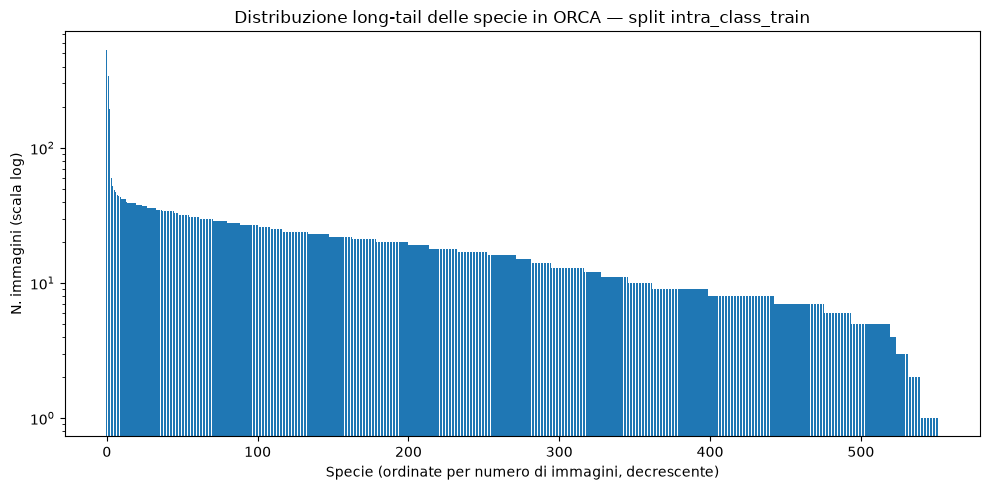

In [6]:
fig, ax = plt.subplots()
ax.bar(range(len(counts)), counts.values)
ax.set_yscale("log")
ax.set_xlabel("Specie (ordinate per numero di immagini, decrescente)")
ax.set_ylabel("N. immagini (scala log)")
ax.set_title("Distribuzione long-tail delle specie in ORCA — split intra_class_train")
plt.tight_layout()
plt.savefig(DOCS_DIR / "orca_long_tail.png", dpi=150)
plt.show()

## 4. Simulazione soglie: quante classi/immagini restano al variare del taglio minimo

Il grafico giustifica con numeri reali la scelta del sottoinsieme di classi per il classificatore.

In [7]:
thresholds = [5, 10, 15, 20, 30, 50, 75, 100]
rows = []
for t in thresholds:
    kept_species = counts[counts >= t]
    rows.append({
        "soglia_min_img_per_specie": t,
        "n_specie_incluse": kept_species.shape[0],
        "n_immagini_totali": int(kept_species.sum()),
    })

threshold_df = pd.DataFrame(rows)
threshold_df

,soglia_min_img_per_specie,n_specie_incluse,n_immagini_totali
0,5,520,10087
1,10,362,8933
2,15,282,7975
3,20,200,6573
4,30,71,3512
5,50,5,1183
6,75,3,1071
7,100,3,1071


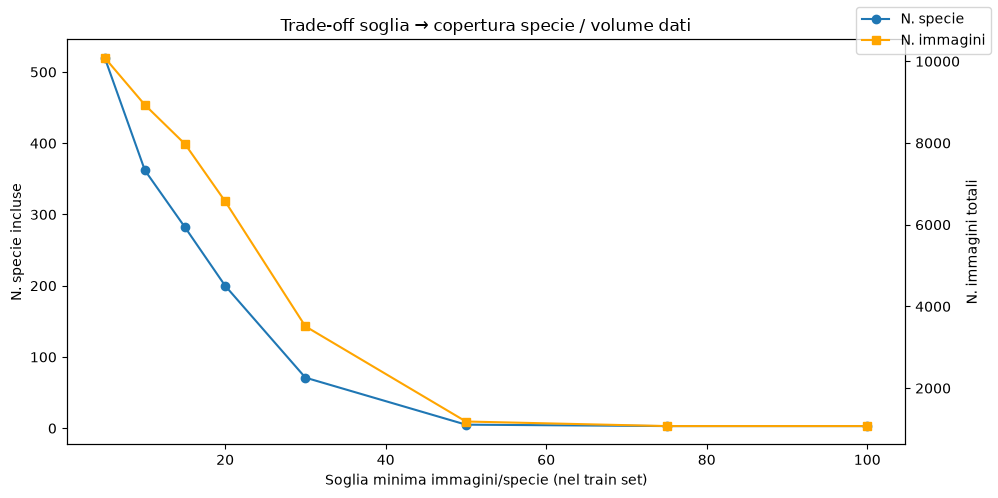

In [8]:
fig, ax1 = plt.subplots()
ax1.plot(threshold_df["soglia_min_img_per_specie"], threshold_df["n_specie_incluse"], marker="o", label="N. specie")
ax1.set_xlabel("Soglia minima immagini/specie (nel train set)")
ax1.set_ylabel("N. specie incluse")
ax2 = ax1.twinx()
ax2.plot(threshold_df["soglia_min_img_per_specie"], threshold_df["n_immagini_totali"], marker="s", color="orange", label="N. immagini")
ax2.set_ylabel("N. immagini totali")
fig.legend(loc="upper right")
plt.title("Trade-off soglia \u2192 copertura specie / volume dati")
plt.tight_layout()
plt.savefig(DOCS_DIR / "orca_threshold_tradeoff.png", dpi=150)
plt.show()

## 5. Scelta della soglia e verifica di copertura sul val set

Non basta scegliere la soglia sul train: bisogna controllare che le stesse classi abbiano anche una presenza sufficiente nel val set ufficiale, altrimenti alcune classi rischiano di avere 0 esempi di validazione.

In [9]:
MIN_IMAGES_PER_SPECIES = 20  # da tarare in base al grafico sopra

selected_species = counts[counts >= MIN_IMAGES_PER_SPECIES].index.tolist()

val_counts = val_df.groupby("common_name")["image_id"].nunique()
coverage = pd.DataFrame({
    "train_images": counts,
    "val_images": val_counts,
}).loc[selected_species].fillna(0).astype(int)

print(f"Classi selezionate (soglia >= {MIN_IMAGES_PER_SPECIES}): {len(selected_species)}")
print(f"Classi con 0 immagini nel val set ufficiale: {(coverage['val_images'] == 0).sum()}")
coverage.sort_values("train_images", ascending=False).head(20)

Classi selezionate (soglia >= 20): 200
Classi con 0 immagini nel val set ufficiale: 0


,train_images,val_images
common_name,,
coral,533,272
fish,343,128
sea anemone,195,63
sea urchin,60,43
emperor angelfish,52,12
moorish idol,49,10
powder blue tang fish,47,5
emperor fish,45,9
dungeness crab,44,11


## 6. Controllo leggero sui duplicati (sanity check, non base dello split)

Lo split ufficiale intra_class ha già zero overlap di immagini tra train e val. Questo controllo serve solo a capire se, *dentro* il train set, esistono immagini quasi identiche (stesso scatto ripetuto) che potrebbero far sovrastimare la copertura reale di una classe.

In [10]:
sample_df = train_df[train_df["common_name"].isin(selected_species)].drop_duplicates(subset="image_id")

hashes = {}
errors = []
for _, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    try:
        with Image.open(row["image_path"]) as img:
            hashes[row["image_id"]] = imagehash.phash(img, hash_size=8)
    except Exception as e:
        errors.append((row["image_id"], str(e)))

print(f"Hashate {len(hashes)} immagini, {len(errors)} errori di lettura")
if errors:
    print("Primo errore:", errors[0])

  0%|          | 0/5863 [00:00<?, ?it/s]

/home/ubuntu/marine_ai/.venv_rocm/lib/python3.12/site-packages/PIL/Image.py:1137: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Hashate 5863 immagini, 0 errori di lettura


In [11]:
DUP_DISTANCE_THRESHOLD = 4
image_ids = list(hashes.keys())
parent = {img_id: img_id for img_id in image_ids}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb

for i in tqdm(range(len(image_ids))):
    for j in range(i + 1, len(image_ids)):
        if hashes[image_ids[i]] - hashes[image_ids[j]] <= DUP_DISTANCE_THRESHOLD:
            union(image_ids[i], image_ids[j])

clusters = defaultdict(list)
for img_id in image_ids:
    clusters[find(img_id)].append(img_id)

cluster_sizes = sorted((len(v) for v in clusters.values()), reverse=True)
n_dup_clusters = sum(1 for s in cluster_sizes if s > 1)
n_images_in_dup_clusters = sum(s for s in cluster_sizes if s > 1)

if image_ids:
    print(f"Cluster con piu' di 1 immagine: {n_dup_clusters}")
    print(f"Immagini coinvolte: {n_images_in_dup_clusters} su {len(image_ids)} ({n_images_in_dup_clusters/len(image_ids):.1%})")
else:
    print("Nessuna immagine hashata: verifica IMAGES_DIR/errori sopra prima di interpretare questa sezione.")

  0%|          | 0/5863 [00:00<?, ?it/s]

Cluster con piu' di 1 immagine: 68
Immagini coinvolte: 137 su 5863 (2.3%)


## 7. Riepilogo numeri per PPT e sinossi

In [12]:
summary = {
    "split_usato": "intra_class (train + val_seen, ufficiale ORCA)",
    "n_specie_totali_split_intra_class": int(counts.shape[0]),
    "n_immagini_train": int(train_df["image_id"].nunique()),
    "n_immagini_val": int(val_df["image_id"].nunique()),
    "overlap_train_val": int(len(overlap)),
    "soglia_scelta": MIN_IMAGES_PER_SPECIES,
    "n_specie_selezionate": len(selected_species),
    "n_immagini_selezionate_train": int(coverage["train_images"].sum()),
    "n_classi_senza_val": int((coverage["val_images"] == 0).sum()),
    "soglie_valutate": rows,
    "pct_immagini_in_cluster_duplicati_sul_selezionato": round(n_images_in_dup_clusters / len(image_ids), 4) if image_ids else None,
}

with open(DOCS_DIR / "orca_summary.json", "w") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

summary

{'split_usato': 'intra_class (train + val_seen, ufficiale ORCA)',
 'n_specie_totali_split_intra_class': 552,
 'n_immagini_train': 9006,
 'n_immagini_val': 2720,
 'overlap_train_val': 0,
 'soglia_scelta': 20,
 'n_specie_selezionate': 200,
 'n_immagini_selezionate_train': 6573,
 'n_classi_senza_val': 0,
 'soglie_valutate': [{'soglia_min_img_per_specie': 5,
   'n_specie_incluse': 520,
   'n_immagini_totali': 10087},
  {'soglia_min_img_per_specie': 10,
   'n_specie_incluse': 362,
   'n_immagini_totali': 8933},
  {'soglia_min_img_per_specie': 15,
   'n_specie_incluse': 282,
   'n_immagini_totali': 7975},
  {'soglia_min_img_per_specie': 20,
   'n_specie_incluse': 200,
   'n_immagini_totali': 6573},
  {'soglia_min_img_per_specie': 30,
   'n_specie_incluse': 71,
   'n_immagini_totali': 3512},
  {'soglia_min_img_per_specie': 50,
   'n_specie_incluse': 5,
   'n_immagini_totali': 1183},
  {'soglia_min_img_per_specie': 75,
   'n_specie_incluse': 3,
   'n_immagini_totali': 1071},
  {'soglia_min_img